             STANDARD (UNWEIGHTED) SVM            
              precision    recall  f1-score   support

    Safe (0)       0.95      1.00      0.98       340
Rockfall (1)       1.00      0.15      0.26        20

    accuracy                           0.95       360
   macro avg       0.98      0.57      0.62       360
weighted avg       0.96      0.95      0.94       360


               CLASS-WEIGHTED SVM                 
              precision    recall  f1-score   support

    Safe (0)       0.98      0.91      0.94       340
Rockfall (1)       0.31      0.70      0.43        20

    accuracy                           0.90       360
   macro avg       0.65      0.80      0.69       360
weighted avg       0.94      0.90      0.92       360



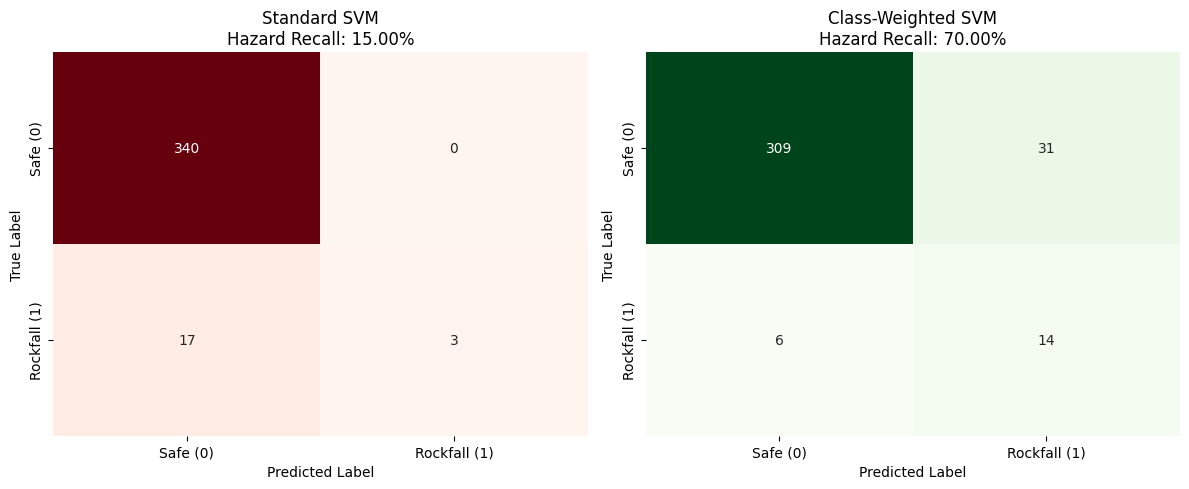

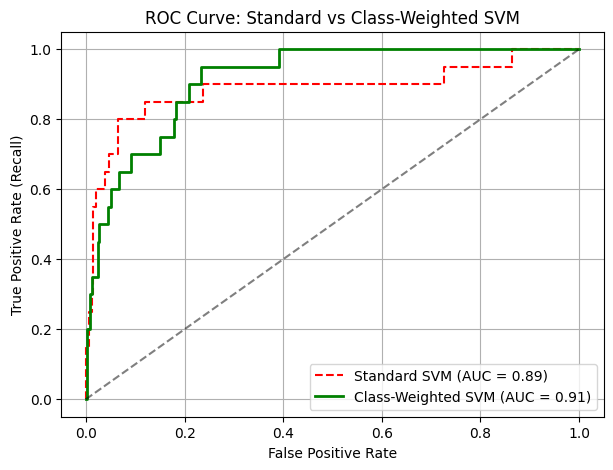

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

# 1. Load Dataset
data = pd.read_csv("data/rockfall_imbalanced_dataset.csv")
X = data.drop(columns=["target"])
y = data["target"]

# 2. Stratified Train-Test Split (preserves rare class proportion)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 3. Scaling Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# MODEL 1: Standard (Unweighted) SVM
# ==========================================
std_svm = SVC(kernel="rbf", C=1.0, probability=True, random_state=42)
std_svm.fit(X_train_scaled, y_train)

y_pred_std = std_svm.predict(X_test_scaled)
y_prob_std = std_svm.predict_proba(X_test_scaled)[:, 1]

# ==========================================
# MODEL 2: Class-Weighted SVM
# ==========================================
class_weighted_svm = SVC(kernel="rbf", C=1.0, class_weight="balanced", probability=True, random_state=42)
class_weighted_svm.fit(X_train_scaled, y_train)

y_pred_cw = class_weighted_svm.predict(X_test_scaled)
y_prob_cw = class_weighted_svm.predict_proba(X_test_scaled)[:, 1]

# ==========================================
# PRINT COMPARATIVE EVALUATION
# ==========================================
print("==================================================")
print("             STANDARD (UNWEIGHTED) SVM            ")
print("==================================================")
print(classification_report(y_test, y_pred_std, target_names=["Safe (0)", "Rockfall (1)"]))

print("\n==================================================")
print("               CLASS-WEIGHTED SVM                 ")
print("==================================================")
print(classification_report(y_test, y_pred_cw, target_names=["Safe (0)", "Rockfall (1)"]))

# ==========================================
# GENERATE PLOTS FOR RESEARCH PAPER
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix 1: Standard SVM
cm_std = confusion_matrix(y_test, y_pred_std)
sns.heatmap(cm_std, annot=True, fmt="d", cmap="Reds", ax=axes[0], cbar=False)
axes[0].set_title(f"Standard SVM\nHazard Recall: {cm_std[1,1]/(cm_std[1,0]+cm_std[1,1]):.2%}")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].set_xticklabels(["Safe (0)", "Rockfall (1)"])
axes[0].set_yticklabels(["Safe (0)", "Rockfall (1)"])

# Confusion Matrix 2: Class-Weighted SVM
cm_cw = confusion_matrix(y_test, y_pred_cw)
sns.heatmap(cm_cw, annot=True, fmt="d", cmap="Greens", ax=axes[1], cbar=False)
axes[1].set_title(f"Class-Weighted SVM\nHazard Recall: {cm_cw[1,1]/(cm_cw[1,0]+cm_cw[1,1]):.2%}")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].set_xticklabels(["Safe (0)", "Rockfall (1)"])
axes[1].set_yticklabels(["Safe (0)", "Rockfall (1)"])

plt.tight_layout()
plt.savefig("confusion_matrix_comparison.png", dpi=300)
plt.show()

# ROC Curve Comparison
fpr_std, tpr_std, _ = roc_curve(y_test, y_prob_std)
fpr_cw, tpr_cw, _ = roc_curve(y_test, y_prob_cw)

auc_std = roc_auc_score(y_test, y_prob_std)
auc_cw = roc_auc_score(y_test, y_prob_cw)

plt.figure(figsize=(7, 5))
plt.plot(fpr_std, tpr_std, label=f"Standard SVM (AUC = {auc_std:.2f})", linestyle="--", color="red")
plt.plot(fpr_cw, tpr_cw, label=f"Class-Weighted SVM (AUC = {auc_cw:.2f})", linewidth=2, color="green")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve: Standard vs Class-Weighted SVM")
plt.legend()
plt.grid(True)
plt.savefig("roc_curve_comparison.png", dpi=300)
plt.show()